In [ ]:

# Gerekli kütüphaneleri içe aktarıyoruz
import pandas as pd
from sklearn.datasets import load_iris

# Iris veri setini yüklüyoruz
iris = load_iris()

# Verileri tabloya dönüştürüyoruz
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Hedef değişkeni ekliyoruz
df["tur"] = iris.target

# İlk 5 satırı görüntülüyoruz
print("IRIS VERİ SETİ - İLK 5 SATIR")
display(df.head())

# Veri setinin boyutunu öğreniyoruz
print("Toplam satır sayısı:", df.shape[0])
print("Toplam sütun sayısı:", df.shape[1])

# Çiçek türlerini görüntülüyoruz
print("Çiçek türleri:", iris.target_names)


IRIS VERİ SETİ - İLK 5 SATIR


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),tur
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Toplam satır sayısı: 150
Toplam sütun sayısı: 5
Çiçek türleri: ['setosa' 'versicolor' 'virginica']


In [ ]:

# Veri setinin genel bilgileri
print("VERİ SETİNİN GENEL BİLGİLERİ")
df.info()

# Eksik değer kontrolü
print("\nEKSİK DEĞER SAYILARI")
print(df.isnull().sum())

# Tekrarlanan satır kontrolü
print("\nTEKRARLANAN SATIR SAYISI")
print(df.duplicated().sum())

# Çiçek türlerinin dağılımı
print("\nÇİÇEK TÜRLERİNİN DAĞILIMI")
print(df["tur"].map(dict(enumerate(iris.target_names))).value_counts())

# Sayısal değişkenlerin istatistikleri
print("\nVERİ SETİNİN İSTATİSTİKSEL ÖZETİ")
display(df.describe())


VERİ SETİNİN GENEL BİLGİLERİ
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   tur                150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

EKSİK DEĞER SAYILARI
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
tur                  0
dtype: int64

TEKRARLANAN SATIR SAYISI
1

ÇİÇEK TÜRLERİNİN DAĞILIMI
tur
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

VERİ SETİNİN İSTATİSTİKSEL ÖZETİ


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),tur
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


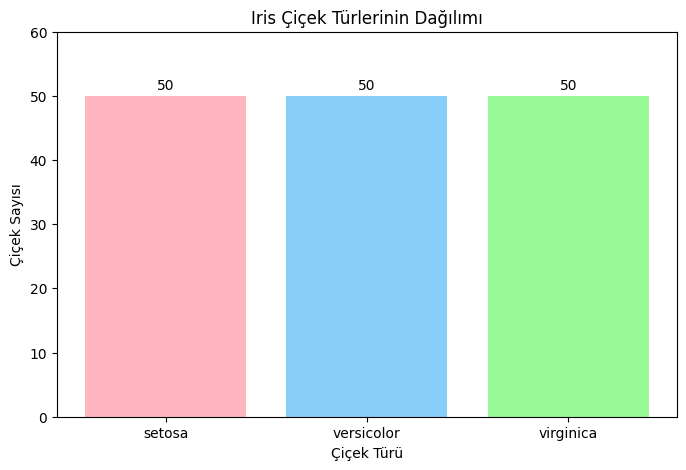

In [ ]:

import matplotlib.pyplot as plt

# Çiçek türlerinin isimlerini oluşturuyoruz
tur_isimleri = df["tur"].map(
    dict(enumerate(iris.target_names))
)

# Her türün sayısını hesaplıyoruz
tur_sayilari = tur_isimleri.value_counts()

# Sütun grafiği oluşturuyoruz
plt.figure(figsize=(8, 5))

plt.bar(
    tur_sayilari.index,
    tur_sayilari.values,
    color=["#FFB6C1", "#87CEFA", "#98FB98"]
)

plt.title("Iris Çiçek Türlerinin Dağılımı")
plt.xlabel("Çiçek Türü")
plt.ylabel("Çiçek Sayısı")

plt.ylim(0, 60)

# Sütunların üzerine sayıları yazıyoruz
for i, sayi in enumerate(tur_sayilari.values):
    plt.text(i, sayi + 1, str(sayi), ha="center")

plt.show()


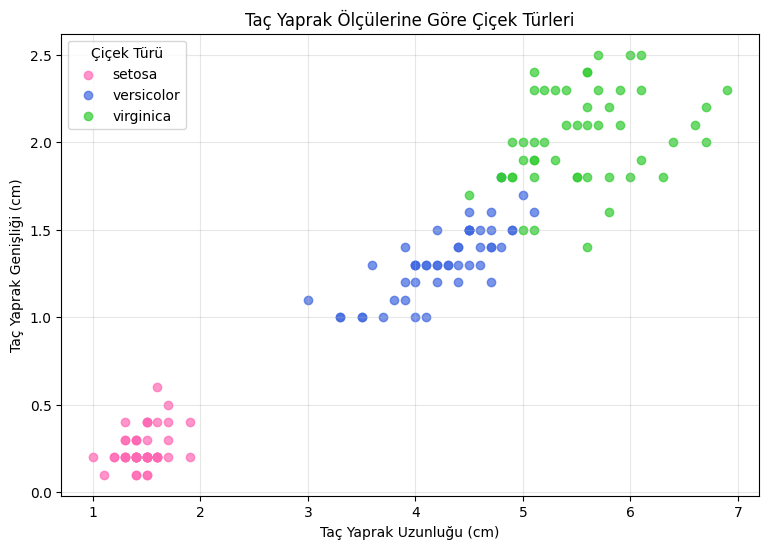

In [ ]:

# İkinci grafik: Taç yaprak ölçümleri

plt.figure(figsize=(9, 6))

renkler = ["#FF69B4", "#4169E1", "#32CD32"]

for i, tur_adi in enumerate(iris.target_names):
    veriler = df[df["tur"] == i]

    plt.scatter(
        veriler["petal length (cm)"],
        veriler["petal width (cm)"],
        label=tur_adi,
        color=renkler[i],
        alpha=0.7
    )

plt.title("Taç Yaprak Ölçülerine Göre Çiçek Türleri")
plt.xlabel("Taç Yaprak Uzunluğu (cm)")
plt.ylabel("Taç Yaprak Genişliği (cm)")
plt.legend(title="Çiçek Türü")
plt.grid(alpha=0.3)

plt.show()


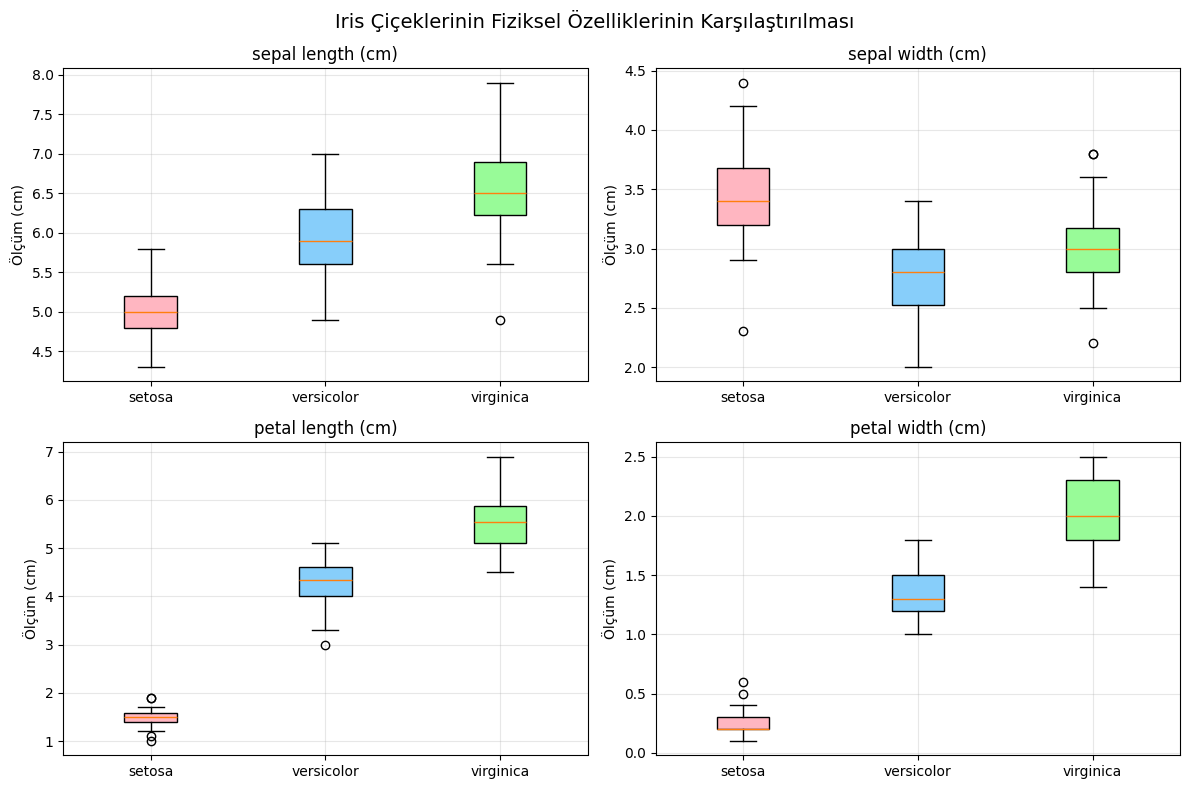

In [ ]:

# Çiçek türlerinin isimlerini ekliyoruz
df["tur_adi"] = df["tur"].map(
    dict(enumerate(iris.target_names))
)

# Dört fiziksel özelliği belirliyoruz
ozellikler = iris.feature_names

# Grafik alanını oluşturuyoruz
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

renkler = ["#FFB6C1", "#87CEFA", "#98FB98"]

# Her özellik için kutu grafiği oluşturuyoruz
for ax, ozellik in zip(axes.flat, ozellikler):
    gruplar = [
        df[df["tur_adi"] == tur][ozellik]
        for tur in iris.target_names
    ]

    kutular = ax.boxplot(
        gruplar,
        tick_labels=iris.target_names,
        patch_artist=True
    )

    for kutu, renk in zip(kutular["boxes"], renkler):
        kutu.set_facecolor(renk)

    ax.set_title(ozellik)
    ax.set_ylabel("Ölçüm (cm)")
    ax.grid(alpha=0.3)

plt.suptitle(
    "Iris Çiçeklerinin Fiziksel Özelliklerinin Karşılaştırılması",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Giriş değişkenleri ve hedef değişken
X = df[iris.feature_names]
y = df["tur"]

# Verileri %80 eğitim, %20 test olarak ayırıyoruz
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Ölçeklendirme işlemi
scaler = StandardScaler()

# Ölçeklendirmeyi yalnızca eğitim verisiyle öğreniyoruz
X_train_scaled = scaler.fit_transform(X_train)

# Test verisine aynı dönüşümü uyguluyoruz
X_test_scaled = scaler.transform(X_test)

# Sonuçları görüntülüyoruz
print("Eğitim veri sayısı:", len(X_train))
print("Test veri sayısı:", len(X_test))

print("\nEğitim verilerinin sınıf dağılımı:")
print(y_train.value_counts().sort_index())

print("\nTest verilerinin sınıf dağılımı:")
print(y_test.value_counts().sort_index())

print("\nÖlçeklendirme başarıyla tamamlandı.")


Eğitim veri sayısı: 120
Test veri sayısı: 30

Eğitim verilerinin sınıf dağılımı:
tur
0    40
1    40
2    40
Name: count, dtype: int64

Test verilerinin sınıf dağılımı:
tur
0    10
1    10
2    10
Name: count, dtype: int64

Ölçeklendirme başarıyla tamamlandı.


In [ ]:

from sklearn.linear_model import LogisticRegression

# Logistic Regression modelini oluşturuyoruz
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Modeli eğitim verileriyle eğitiyoruz
model.fit(X_train_scaled, y_train)

# Test verileri üzerinde tahmin yapıyoruz
y_pred = model.predict(X_test_scaled)

print("Model başarıyla eğitildi!")
print("Test veri sayısı:", len(y_pred))

print("\nİlk 10 gerçek çiçek türü:")
print(y_test.values[:10])

print("\nİlk 10 tahmin edilen çiçek türü:")
print(y_pred[:10])


Model başarıyla eğitildi!
Test veri sayısı: 30

İlk 10 gerçek çiçek türü:
[0 2 1 1 0 1 0 0 2 1]

İlk 10 tahmin edilen çiçek türü:
[0 2 1 1 0 1 0 0 2 1]


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Modelin başarı metriklerini hesaplıyoruz
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

# Sonuçları yazdırıyoruz
print("MODEL DEĞERLENDİRME SONUÇLARI")
print("------------------------------")

print(f"Doğruluk (Accuracy): %{accuracy * 100:.2f}")
print(f"Kesinlik (Precision): {precision:.4f}")
print(f"Duyarlılık (Recall): {recall:.4f}")
print(f"F1 Skoru: {f1:.4f}")

# Her çiçek türünün ayrı ayrı başarısını gösteriyoruz
print("\nSINIFLANDIRMA RAPORU")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names,
        zero_division=0
    )
)


MODEL DEĞERLENDİRME SONUÇLARI
------------------------------
Doğruluk (Accuracy): %93.33
Kesinlik (Precision): 0.9333
Duyarlılık (Recall): 0.9333
F1 Skoru: 0.9333

SINIFLANDIRMA RAPORU
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [ ]:

from sklearn.linear_model import LogisticRegression

# Logistic Regression modelini oluşturuyoruz
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Modeli eğitim verileriyle eğitiyoruz
model.fit(X_train_scaled, y_train)

# Test verileri üzerinde tahmin yapıyoruz
y_pred = model.predict(X_test_scaled)

print("Model başarıyla eğitildi!")
print("Test veri sayısı:", len(y_pred))

print("\nİlk 10 gerçek çiçek türü:")
print(y_test.values[:10])

print("\nİlk 10 tahmin edilen çiçek türü:")
print(y_pred[:10])


Model başarıyla eğitildi!
Test veri sayısı: 30

İlk 10 gerçek çiçek türü:
[0 2 1 1 0 1 0 0 2 1]

İlk 10 tahmin edilen çiçek türü:
[0 2 1 1 0 1 0 0 2 1]


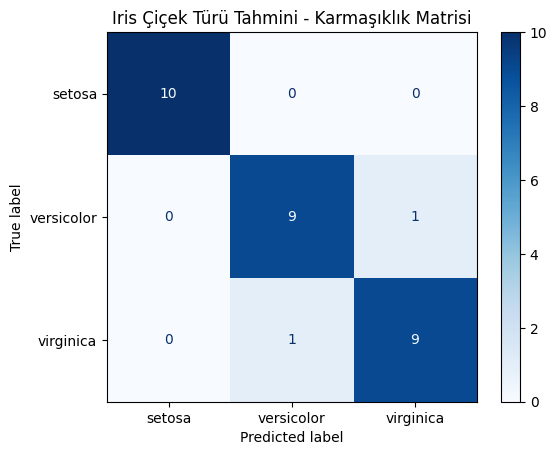

Karmaşıklık Matrisi:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Karmaşıklık matrisini hesapla
cm = confusion_matrix(y_test, y_pred)

# Grafiği oluştur
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Iris Çiçek Türü Tahmini - Karmaşıklık Matrisi")
plt.show()

print("Karmaşıklık Matrisi:")
print(cm)
